# Noise Sensitivity — Synthetic Data Generation (40-warming-event regime)

**Goal:** generate a third fixed-dynamics `Melcher25` regime, alongside the existing
~15-warming-event regime (`ngrip_calibrated_noise_sensitivity_data/`, `sigma=0.37`) and
~25-warming-event regime (`noise_sensitivity_data/`, `sigma=0.5`), this time targeting
**~40 warming (stadial→interstadial) events** over the same 120 kyr window — to give
`build_train_test_split.ipynb` a wider range of training-set event-count regimes to
build separate training sets from.

**Important distinction this notebook is careful about:** earlier work in this project
sometimes scored/labeled datasets by *total* state transitions (warming + cooling, i.e.
`np.diff(state) != 0`) while comparing against NGRIP's DO catalog, which counts
*warming-only* onsets (`np.diff(state) == -1`). Total transitions run almost exactly
2x the warming-only count. This notebook targets and reports **warming-only** counts
throughout, and also records total transitions in the manifest for reference.

**Parameter choice:** `gamma=1.5` and `alpha=-0.5` are kept fixed at the same values used
by both existing regimes (mid-range of Melcher et al. 2025's constraints, matching the
package default and avoiding the `alpha=0` instability boundary). Only `sigma` differs —
calibrated empirically below (20-seed sweep) to hit a ~40 warming-event mean, since no
existing parameter search in this repo covers this higher-event-count region.

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from climatecritters.model_critters.melcher25 import Melcher25, classify_bistable_states
from climatecritters.utils.noise import from_param

## Section 1 — Calibrate sigma for a ~40 warming-event mean

In [2]:
GAMMA = 1.5   # fixed, matching both existing regimes
ALPHA = -0.5  # fixed, matching both existing regimes

T_SPAN = (0, 120)   # kyr, matches NGRIP glacial-period coverage, same as both existing regimes
DT     = 0.02
Y0     = [1.0, 0.0]


def warming_count(sigma, seed):
    model = Melcher25(sigma=sigma, gamma=GAMMA, alpha=ALPHA)
    out = model.integrate(t_span=T_SPAN, y0=Y0, method='heun_maruyama', dt=DT,
                           kwargs={'random_seed': seed, 'si': DT})
    states = np.asarray(out.diagnostic_variables['states'])
    return int((np.diff(states) == -1).sum())


sweep_rows = []
for sigma in [0.5, 0.55, 0.6, 0.65, 0.68, 0.7, 0.72, 0.75, 0.8]:
    warm = [warming_count(sigma, seed) for seed in range(10)]
    sweep_rows.append(dict(sigma=sigma, mean_warming=np.mean(warm), min=min(warm), max=max(warm)))

sweep_df = pd.DataFrame(sweep_rows)
print(sweep_df.to_string(index=False, float_format='{:.2f}'.format))

 sigma  mean_warming  min  max
  0.50         21.80   18   25
  0.55         27.20   24   31
  0.60         32.30   28   35
  0.65         36.70   31   40
  0.68         39.70   36   44
  0.70         41.30   38   45
  0.72         44.10   40   50
  0.75         46.70   43   52
  0.80         51.80   44   57


`sigma=0.68` sits closest to the 40-event target (10-seed mean ≈39.7). Confirmed below
across the full 20-seed ensemble that will actually be used for generation, and checked
that dwell times stay well-behaved (no collapse to near-continuous chatter) rather than
drifting into random-walk-like behavior.

In [3]:
SIGMA = 0.68

warm_20 = []
for seed in range(20):
    model = Melcher25(sigma=SIGMA, gamma=GAMMA, alpha=ALPHA)
    out = model.integrate(t_span=T_SPAN, y0=Y0, method='heun_maruyama', dt=DT,
                           kwargs={'random_seed': seed, 'si': DT})
    states = np.asarray(out.diagnostic_variables['states'])
    warm_20.append(int((np.diff(states) == -1).sum()))

print(f"sigma={SIGMA}: 20-seed warming-event mean={np.mean(warm_20):.1f}, "
      f"range={min(warm_20)}-{max(warm_20)}")
print(f"Per-seed warming counts: {warm_20}")

sigma=0.68: 20-seed warming-event mean=39.0, range=26-48
Per-seed warming counts: [41, 38, 40, 39, 39, 41, 44, 36, 37, 42, 41, 41, 26, 48, 44, 32, 39, 38, 40, 34]


## Section 2 — Colored-Noise Generation

Same `from_param` colored-noise utility, same SNR-level formula (`sigma_noise = gap/k`), as `Generate_Data_25events.ipynb`. `gap` depends on `alpha` (unchanged here), so it comes out identical to the other two regimes.

In [4]:
OUT_DIR = "/Users/maryamniati/Documents/Syntheticdata/ngrip_40events_noise_sensitivity_data"
os.makedirs(OUT_DIR, exist_ok=True)


def transition_times_from_states(time, states):
    change_idx = np.where(np.diff(states) != 0)[0] + 1
    return time[change_idx]


def warming_times_from_states(time, states):
    idx = np.where(np.diff(states) == -1)[0] + 1
    return time[idx]


_check_model = Melcher25(sigma=SIGMA, gamma=GAMMA, alpha=ALPHA)
_check_output = _check_model.integrate(t_span=T_SPAN, y0=Y0, method='heun_maruyama', dt=DT,
                                        kwargs={'random_seed': 0, 'si': DT})
_check_db = np.asarray(_check_output.state_variables['db'])
_check_states = np.asarray(_check_output.diagnostic_variables['states'])
assert np.all(np.isfinite(_check_db)), "Fixed configuration produced non-finite values"
gap = _check_model.interstadial_threshold - _check_model.stadial_threshold
print(f"Fixed config sanity check: {len(_check_db)} points, finite=True, "
      f"{int(np.sum(np.diff(_check_states) != 0))} total transitions, "
      f"{int(np.sum(np.diff(_check_states) == -1))} warming, "
      f"thresholds=({_check_model.stadial_threshold:.3f}, {_check_model.interstadial_threshold:.3f}), gap={gap:.5f}")

NOISE_COLORS = {'white': 0.0, 'pink': 1.0, 'red': 2.0}
NOISE_LEVELS = {'snr4': gap / 4, 'snr3': gap / 3, 'snr2': gap / 2}
N_SEEDS = 20


def generate_colored_noise(beta, amplitude, length, seed):
    surr = from_param(method='CN', noise_param=[beta], length=length, number=1, seed=seed)
    return surr.series_list[0].standardize(scale=amplitude).value


def simulate_condition(beta, amplitude, base_seed, noise_seed):
    model = Melcher25(sigma=SIGMA, gamma=GAMMA, alpha=ALPHA)
    output = model.integrate(t_span=T_SPAN, y0=Y0, method='heun_maruyama', dt=DT,
                              kwargs={'random_seed': base_seed, 'si': DT})
    time = output.time
    db_true = np.asarray(output.state_variables['db']).copy()
    true_states = np.asarray(output.diagnostic_variables['states']).copy()

    noise = generate_colored_noise(beta, amplitude, length=len(db_true), seed=noise_seed)
    output.add_noise('db', noise)
    db_noisy = np.asarray(output.state_variables['db'])

    observed_states = classify_bistable_states(db_noisy, alpha=ALPHA)
    return time, db_true, db_noisy, true_states, observed_states

Fixed config sanity check: 6001 points, finite=True, 81 total transitions, 41 warming, thresholds=(1.023, 1.375), gap=0.35190


## Section 3 — Build the Noise Grid

3 colors x 3 SNR levels x 20 seeds = 180 realizations, identical structure to the other two regimes. Ground truth (`base_seed`) is shared across all 9 (color, level) conditions per seed index -- only the added noise differs.

In [5]:
color_items = list(NOISE_COLORS.items())
level_items = list(NOISE_LEVELS.items())

summary_rows = []
grid_data = {}

for ci, (color_name, beta) in enumerate(color_items):
    for li, (level_name, amplitude) in enumerate(level_items):
        time_ref = None
        db_true_stack, db_noisy_stack = [], []
        state_true_stack, state_observed_stack = [], []

        for s in range(N_SEEDS):
            base_seed = s
            noise_seed = 1000 * (ci * len(level_items) + li) + s

            time, db_true, db_noisy, true_states, obs_states = simulate_condition(
                beta, amplitude, base_seed=base_seed, noise_seed=noise_seed)

            if time_ref is None:
                time_ref = time

            db_true_stack.append(db_true)
            db_noisy_stack.append(db_noisy)
            state_true_stack.append(true_states)
            state_observed_stack.append(obs_states)

            true_trans = transition_times_from_states(time, true_states)
            obs_trans = transition_times_from_states(time, obs_states)
            true_warm = warming_times_from_states(time, true_states)
            obs_warm = warming_times_from_states(time, obs_states)
            summary_rows.append(dict(
                color=color_name, level=level_name, amplitude=amplitude, seed=s,
                n_true_transitions=len(true_trans),
                n_observed_transitions=len(obs_trans),
                n_true_warming=len(true_warm),
                n_observed_warming=len(obs_warm),
            ))

        grid_data[(color_name, level_name)] = dict(
            time=time_ref,
            db_true=np.vstack(db_true_stack),
            db_noisy=np.vstack(db_noisy_stack),
            state_true=np.vstack(state_true_stack),
            state_observed=np.vstack(state_observed_stack),
        )
        print(f"Done: color={color_name:5s} level={level_name:6s} (amplitude={amplitude:.4f})")

summary_df = pd.DataFrame(summary_rows)
print(f"\nCompleted {len(summary_df)} realizations across {len(grid_data)} conditions")

Done: color=white level=snr4   (amplitude=0.0880)


Done: color=white level=snr3   (amplitude=0.1173)


Done: color=white level=snr2   (amplitude=0.1760)


Done: color=pink  level=snr4   (amplitude=0.0880)


Done: color=pink  level=snr3   (amplitude=0.1173)


Done: color=pink  level=snr2   (amplitude=0.1760)


Done: color=red   level=snr4   (amplitude=0.0880)


Done: color=red   level=snr3   (amplitude=0.1173)


Done: color=red   level=snr2   (amplitude=0.1760)

Completed 180 realizations across 9 conditions


In [6]:
# Warming-only event counts per combo (this is the number that matters for build_train_test_split)
summary_df.groupby(['color', 'level'])[['n_true_warming', 'n_observed_warming']].mean()

n_true_warming  n_observed_warming
color level                                    
pink  snr2             39.0               58.30
      snr3             39.0               46.00
      snr4             39.0               41.65
red   snr2             39.0               40.40
      snr3             39.0               41.10
      snr4             39.0               40.20
white snr2             39.0              115.40
      snr3             39.0               60.35
      snr4             39.0               49.75

## Section 4 — Qualitative Visual Check

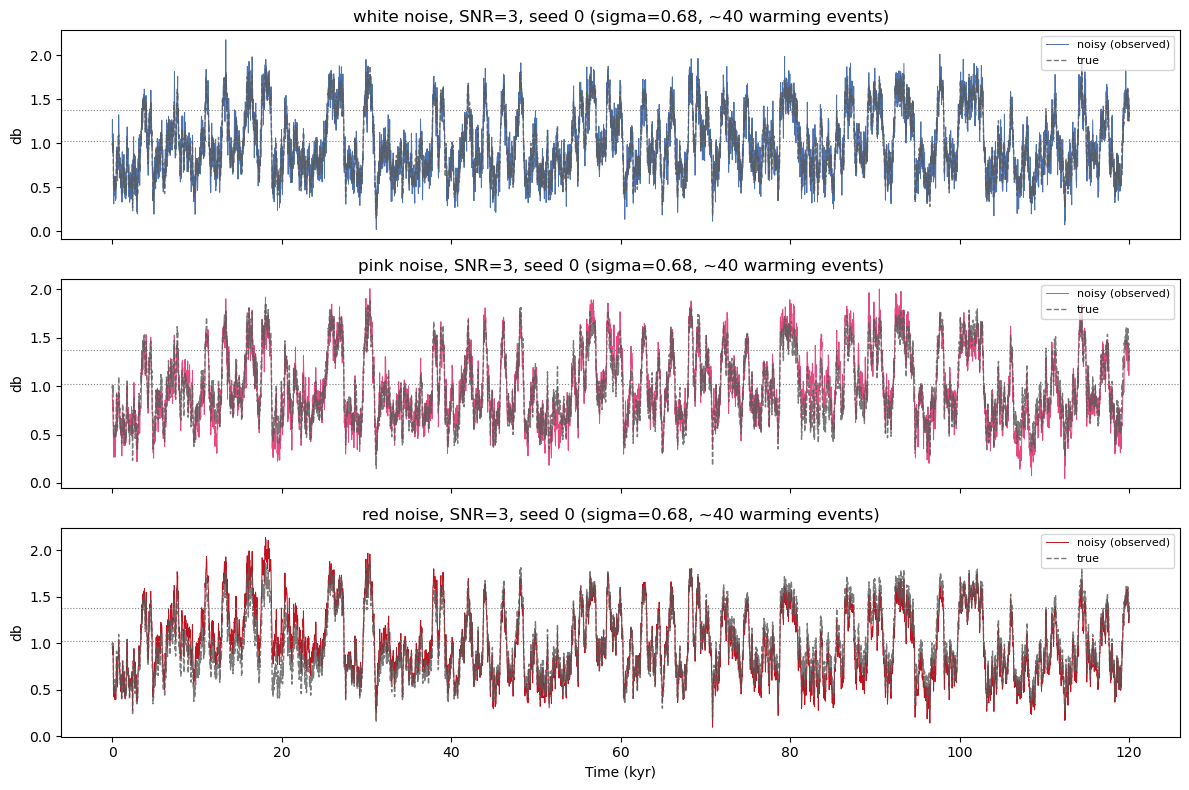

In [7]:
NOISE_PLOT_COLORS = {'white': '#4c72b0', 'pink': '#e64980', 'red': '#c1121f'}
TRUE_COLOR = '#595959'

fig, axes = plt.subplots(len(NOISE_COLORS), 1, figsize=(12, 8), sharex=True)

for ax, color_name in zip(axes, NOISE_COLORS):
    d = grid_data[(color_name, 'snr3')]
    ax.plot(d['time'], d['db_noisy'][0], lw=0.7, color=NOISE_PLOT_COLORS[color_name], label='noisy (observed)')
    ax.plot(d['time'], d['db_true'][0], lw=1.0, color=TRUE_COLOR, ls='--', alpha=0.8, label='true')
    ax.axhline(_check_model.stadial_threshold, color='gray', ls=':', lw=0.8)
    ax.axhline(_check_model.interstadial_threshold, color='gray', ls=':', lw=0.8)
    ax.set_ylabel('db')
    ax.set_title(f"{color_name} noise, SNR=3, seed 0 (sigma={SIGMA}, ~40 warming events)")
    ax.legend(fontsize=8, loc='upper right')

axes[-1].set_xlabel('Time (kyr)')
plt.tight_layout()
plt.show()

## Section 5 — Save Datasets

In [8]:
for (color_name, level_name), d in grid_data.items():
    np.savez(
        f"{OUT_DIR}/noise_{color_name}_{level_name}.npz",
        time=d['time'], db_true=d['db_true'], db_noisy=d['db_noisy'],
        state_true=d['state_true'], state_observed=d['state_observed'],
        seeds=np.arange(N_SEEDS),
    )

summary_df.to_csv(f"{OUT_DIR}/noise_grid_manifest.csv", index=False)

with open(f"{OUT_DIR}/noise_grid_config.json", "w") as f:
    json.dump(dict(
        sigma=SIGMA, gamma=GAMMA, alpha=ALPHA,
        source="sigma calibrated via 20-seed sweep to hit ~40 mean warming-only events "
               "(gamma/alpha fixed, matching ngrip_calibrated (~15) and noise_sensitivity_data (~25) regimes)",
        t_span=T_SPAN, dt=DT, y0=Y0,
        noise_colors=NOISE_COLORS, noise_levels=NOISE_LEVELS, n_seeds=N_SEEDS,
        gap=gap,
    ), f, indent=2)

print(f"Saved {len(grid_data)} condition files + manifest + config to {OUT_DIR}")

Saved 9 condition files + manifest + config to /Users/maryamniati/Documents/Syntheticdata/ngrip_40events_noise_sensitivity_data
